# PRIM — Facility Pooling (fac=1, amb=0)

Find where T1 mortality > 0.


In [1]:
import sys
from pathlib import Path
_root = Path(".").resolve()
while not (_root / "paths.py").exists():
    _root = _root.parent
sys.path.insert(0, str(_root))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

RESULTS_PATH = _root / "data_cluster/saltelli_with_wrong_pooling_columns/results.csv"
df = pd.read_csv(RESULTS_PATH)
print(f"Loaded {len(df)} runs")

UNCERTAINTIES = ["ccp_r1_same_bn_min", "ccp_r1_inter_bn_min", "bcas_rate", "waves_per_day", "wave_duration_min"]

sub = df[(df["facility_eligibility"] == 1) & (df["ambulance_eligibility"] == 0)].reset_index(drop=True)
print(f"Policy: Facility Pooling (fac=1, amb=0), {len(sub)} runs")
print(f"T1 mortality range: {sub['death_rate_T1_BCAS'].min():.4f} - {sub['death_rate_T1_BCAS'].max():.4f}")
print(f"Nonzero: {(sub['death_rate_T1_BCAS'] > 0).sum()} / {len(sub)} ({(sub['death_rate_T1_BCAS'] > 0).mean():.1%})")


Loaded 98304 runs
Policy: Facility Pooling (fac=1, amb=0), 24576 runs
T1 mortality range: 0.0000 - 1.0000
Nonzero: 22834 / 24576 (92.9%)


## PRIM — Where does T1 mortality occur?


Cases of interest: 22834 / 24576 (92.9%)



Selected box:
coverage        0.579355
density         0.995111
id             11.000000
k           13229.000000
mass            0.540934
mean            0.995111
n           13294.000000
res_dim         4.000000
Name: 11, dtype: float64

                        box 11                                    
                           min        max       qp value  qp value
wave_duration_min     1.000000  57.500000            NaN  0.156207
bcas_rate             0.023598   0.069993  2.615369e-315       NaN
ccp_r1_same_bn_min   10.500000  20.000000   2.013430e-01       NaN
ccp_r1_inter_bn_min  17.500000  34.500000   3.835632e-01  0.478741



[None]

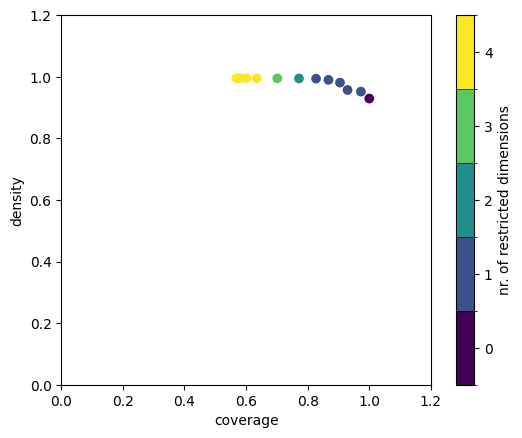

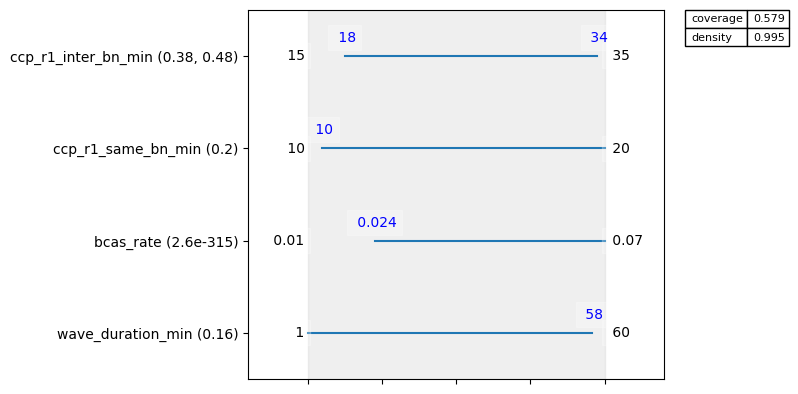

In [2]:
from ema_workbench.analysis import prim

x = sub[UNCERTAINTIES].astype(float)
y = sub["death_rate_T1_BCAS"].values > 0

print(f"Cases of interest: {y.sum()} / {len(y)} ({y.mean():.1%})")

p = prim.Prim(x, y, threshold=0.5)
box = p.find_box()
box.show_tradeoff()
print("\nSelected box:")
box.inspect(style="graph")
box.inspect()
